In [1]:
2+2

4

In [4]:
import os 
import random
import requests
from typing import Annotated
from typing_extensions import TypedDict
from dotenv import load_dotenv
from IPython.display import Image, display
from langchain_openai import ChatOpenAI
from langchain_community.tools import GoogleSerperRun
from langchain_community.utilities import GoogleSerperAPIWrapper
from langchain_core.tools import tool
from langgraph.graph import StateGraph, START ,END
from langgraph.graph.message import add_messages
from langgraph.prebuilt import ToolNode, tools_condition
from langgraph.checkpoint.memory import MemorySaver
#from langgraph.checkpoint.sqlite import SqliteSaver


In [10]:
class State(TypedDict):
    messages: Annotated[list, add_messages]
    

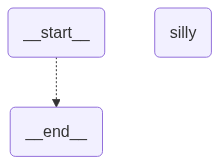

In [11]:
nouns = ["Cabbages", "Unicorns", "Toasters", "Penguins", "Bananas", "Eels", "Pickles"]
adjectives = ["outrageous", "smelly", "pedantic", "existential", "sparkly", "haunted"]

def silly_node(state: State) -> dict:
    sentence = f'{random.choice(nouns)} are {random.choice(adjectives)}'
    return {"messages":[{"role":"assistant","content":sentence}]}

builder = StateGraph(State)
builder.add_node('silly',silly_node)
builder.add_edge(START,END)
builder.add_edge("silly",END)
graph = builder.compile()

display(Image(graph.get_graph().draw_mermaid_png()))

In [12]:
result = graph.invoke({'messages':[{'role':"user","content":"say something"}]})
print(result['messages'][-1].content)

say something


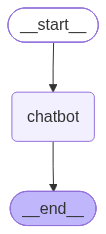

In [13]:
llm = ChatOpenAI(model='gpt-3.5-turbo')

def chatbot_node(state: State) -> dict:
    return{'messages':[llm.invoke(state['messages'])]}

builder = StateGraph(State)
builder.add_node('chatbot',chatbot_node)
builder.add_edge(START,'chatbot')
builder.add_edge('chatbot', END)
graph = builder.compile()

display(Image(graph.get_graph().draw_mermaid_png()))

In [14]:
result=graph.invoke({'messages':[{'role':'user',"content":"what is a directed graph?"}]})
print(result['messages'][-1].content)

A directed graph is a type of graph in which edges have an associated direction, meaning they are directed from one vertex to another. This means that the relationship between nodes is one-way, rather than bidirectional as in an undirected graph. Directed graphs are also known as digraphs and are commonly used in various fields such as computer science, network theory, and mathematics to model relationships and dependencies between different entities.


In [18]:
from langchain_community.tools import DuckDuckGoSearchRun
search=DuckDuckGoSearchRun()
class State(TypedDict):
    messages: Annotated[list, add_messages]
 
llm=ChatOpenAI(model='gpt-3.5-turbo')
tools=[search]
llm_with_tools = llm.bind_tools(tools)

def chatbot_node(state: State) -> dict:
    return {"messages": [llm_with_tools.invoke(state['messages'])]}

builder = StateGraph(State)
builder.add_node("chatbot", chatbot_node)
builder.add_node("tools", ToolNode(tools))
builder.add_edge(START, 'chatbot')
builder.add_conditional_edges('chatbot', tools_condition)
builder.add_edge("tools", "chatbot")
graph = builder.compile()
result=graph.invoke({'messages': [{"role":'user', "content":"how Elon musk new tesla car fly"}]})
print(result["messages"][-1].content)

Elon Musk recently unveiled a new Tesla Roadster car that can fly and accelerate from 0 to 60mph in just 0.81 seconds. The Roadster uses a "fan suction system" on the underside of the vehicle that can pull up to 2 Gs to make the car go upside down. The car can drive upside down on a ramp and perform a mid-air flip. It features jet accelerators powered by compressed air, small wings, and a steering wheel like an airplane. Musk described it as a car that can "basically fly like a rocket," but he mentioned that it's not necessarily a safety-optimized car.
